# 01 - Deutsch-Jozsa

**Question:** a hidden function `f` is either *constant* (same output for every input) or *balanced* (0 for half the inputs, 1 for the other half). Which one is it?

- Classical: up to 2^(m-1) + 1 calls to be sure.
- Quantum (Deutsch-Jozsa): **one** call to the oracle.

`m = n_qubits - 1` input qubits plus 1 helper qubit (10 qubits = 9 inputs + 1 helper).

**Answer rule:** measure the input qubits. All zeros means *constant*; anything else means *balanced*.

**Score:** P(correct answer). Ideal = 1.0, classical baseline = 1/2. Pass rule: measured >= 50% of ideal.

In [7]:
import matplotlib.pyplot as plt
from qiskit import qasm2
from qiskit.visualization import plot_histogram

from noisy_qubits.algorithms import deutsch_jozsa as dj
from noisy_qubits.noise import build_noise_model, slider_label, NOISE_TYPES

def passed(r, fraction=0.5):
    """Pass rule (Section 9.1): measured >= 50% of the ideal score."""
    return r.score >= fraction * r.ideal_score

Expected: balanced; answer: balanced; score: 1.000


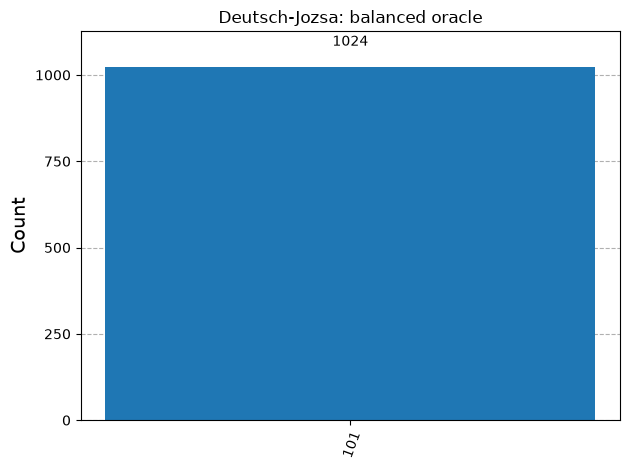

In [8]:
demo_result = dj.run(4, 1024, oracle="balanced", mask=0b101, seed=7)
print(
    f"Expected: {demo_result.meta['expected']}; "
    f"answer: {demo_result.meta['answer']}; "
    f"score: {demo_result.score:.3f}"
)
demo_result.circuit.draw(output="mpl")
plot_histogram(demo_result.counts, title="Deutsch-Jozsa: balanced oracle")

## 1. The circuit

Steps: X on the helper, H on every qubit, oracle, H on the inputs, measure the inputs.
The balanced oracle is `f(x) = mask . x (mod 2)`: a CX from every input whose mask bit is 1.

{'expected': 'balanced', 'oracle': 'balanced', 'mask': 5, 'n_inputs': 3}


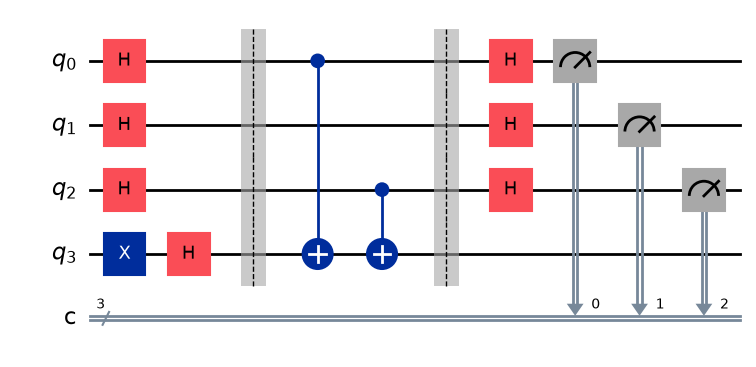

In [9]:
qc = dj.build(n_qubits=4, oracle="balanced", mask=0b101)
print(qc.metadata)
qc.draw("mpl")

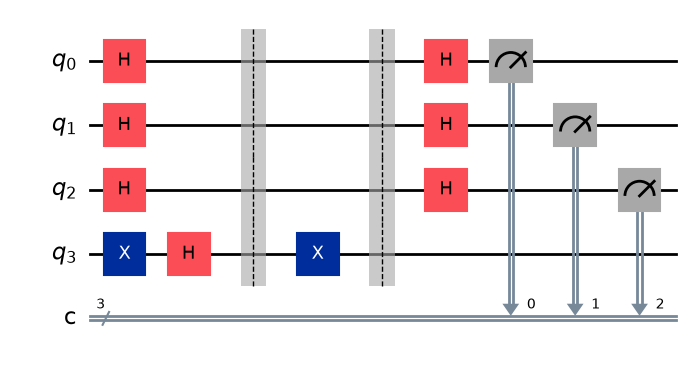

In [10]:
dj.build(n_qubits=4, oracle="constant-1").draw("mpl")

## 2. Ideal (no noise) results at 10 qubits

In [11]:
for oracle in dj.ORACLES:
    r = dj.run(10, 1024, oracle=oracle, seed=7)
    print(f"{oracle:11s} expected={r.meta['expected']:9s} answer={r.meta['answer']:9s} "
          f"score={r.score:.3f} ideal={r.ideal_score:.3f} normalized={r.normalized:.2f} passed={passed(r)}")

constant-0  expected=constant  answer=constant  score=1.000 ideal=1.000 normalized=1.00 passed=True
constant-1  expected=constant  answer=constant  score=1.000 ideal=1.000 normalized=1.00 passed=True
balanced    expected=balanced  answer=balanced  score=1.000 ideal=1.000 normalized=1.00 passed=True


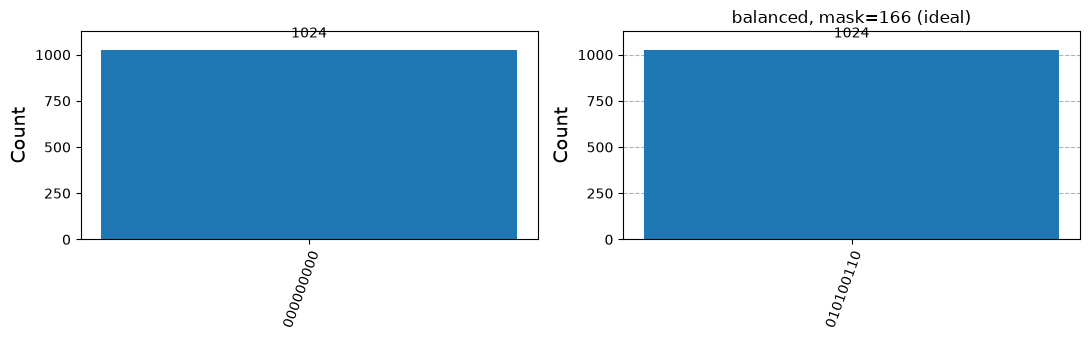

In [12]:
const = dj.run(10, 1024, oracle="constant-0", seed=7)
bal = dj.run(10, 1024, oracle="balanced", seed=7)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_histogram(const.counts, ax=axes[0], title="constant-0 (ideal)")
plot_histogram(bal.counts, ax=axes[1], title=f"balanced, mask={bal.meta['mask']} (ideal)")
plt.tight_layout()

Constant gives `000000000` every time. Balanced **never** gives `000000000`, because the amplitude of all-zeros cancels exactly.

## 3. Typed oracle (truth table)

For `m` input bits the table has `2**m` characters, `table[x] = f(x)`, and bit `i` of `x` is qubit `i`.
It must be constant or balanced, otherwise `InputError`.

In [13]:
r = dj.run(3, 512, truth_table="0110", seed=1)     # 2 input bits, balanced
print(r.meta["expected"], r.meta["answer"], r.score)

try:
    dj.build(3, truth_table="0001")                # neither constant nor balanced
except dj.InputError as e:
    print("Rejected:", e)

balanced balanced 1.0
Rejected: Function must be constant (all 0 or all 1) or balanced (exactly half of the outputs are 1).


## 4. Gate noise (uniform depolarizing, from `noisy_qubits.noise`)

The slider (1 to 100) gives two-qubit error `5% x slider/100` and single-qubit error one tenth of that.

In [14]:
for s in (1, 20, 50, 100):
    nm = build_noise_model("uniform", s)
    c = dj.run(10, 1024, nm, oracle="constant-0", seed=3)
    b = dj.run(10, 1024, nm, oracle="balanced", seed=3)
    print(f"{slider_label('uniform', s):32s} constant={c.score:.3f}  balanced={b.score:.3f}")

Slider 1 means 0.05% error per gate constant=1.000  balanced=1.000
Slider 20 means 1% error per gate constant=0.992  balanced=0.996
Slider 50 means 2.5% error per gate constant=0.974  balanced=0.987
Slider 100 means 5% error per gate constant=0.957  balanced=0.983


## 5. Score vs noise slider

Dashed line: classical baseline (1/2). Dotted line: pass line (50% of ideal).
For DJ these are the same height, so "PASS" is no better than guessing. Simon's has the same issue (noted in the plan).

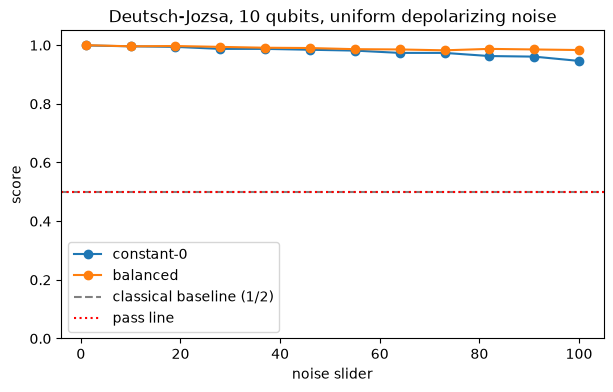

In [15]:
sliders = list(range(1, 101, 9))
res = {k: [] for k in ("constant-0", "balanced")}
for s in sliders:
    nm = build_noise_model("uniform", s)
    for k in res:
        res[k].append(dj.run(10, 1024, nm, oracle=k, seed=s).score)

plt.figure(figsize=(7, 4))
for k, v in res.items():
    plt.plot(sliders, v, marker="o", label=k)
plt.axhline(dj.BASELINE, ls="--", c="grey", label="classical baseline (1/2)")
plt.axhline(0.5, ls=":", c="red", label="pass line")
plt.xlabel("noise slider"); plt.ylabel("score"); plt.ylim(0, 1.05)
plt.legend(); plt.title("Deutsch-Jozsa, 10 qubits, uniform depolarizing noise")
plt.show()

**Reading the chart**

- Both curves stay far above the pass line, even at slider 100.
- The *constant* oracle has **no two-qubit gates** (only H and X), so it only feels the small single-qubit error.
- The *balanced* oracle has up to 9 CX gates, but a noisy output is almost never exactly all zeros, so it is still classified as *balanced*.

Under gate noise alone DJ is very robust, like the Superposition control case. What can break it: **readout error** (next sections) and, on fake devices, the SWAPs added by qubit mapping.

## 6. All noise types at slider 50

In [16]:
print(f"{'noise type':18s} constant  balanced")
for t in NOISE_TYPES:
    nm = build_noise_model("uniform", 50, t)
    c = dj.run(10, 1024, nm, oracle="constant-0", seed=1).score
    b = dj.run(10, 1024, nm, oracle="balanced", seed=1).score
    print(f"{t:18s} {c:.3f}    {b:.3f}")

noise type         constant  balanced
depolarizing       0.970    0.985
bit_flip           0.970    0.997
phase_flip         0.970    0.997
amplitude_damping  0.995    0.992
readout            0.795    1.000


## 7. Readout error breaks the constant case

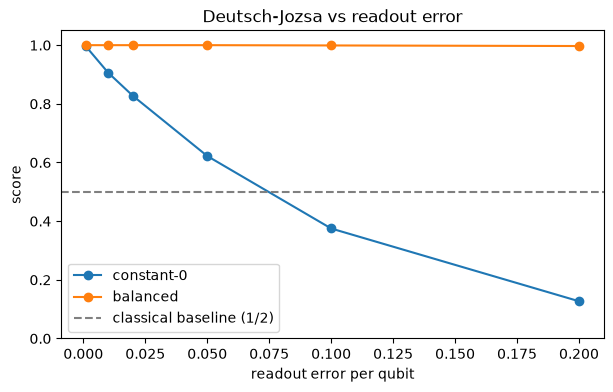

In [17]:
rs = [0.001, 0.01, 0.02, 0.05, 0.1, 0.2]
cs, bs = [], []
for r_ in rs:
    nm = build_noise_model("uniform", 1, "readout", readout=r_)
    cs.append(dj.run(10, 1024, nm, oracle="constant-0", seed=1).score)
    bs.append(dj.run(10, 1024, nm, oracle="balanced", seed=1).score)

plt.figure(figsize=(7, 4))
plt.plot(rs, cs, marker="o", label="constant-0")
plt.plot(rs, bs, marker="o", label="balanced")
plt.axhline(dj.BASELINE, ls="--", c="grey", label="classical baseline (1/2)")
plt.xlabel("readout error per qubit"); plt.ylabel("score"); plt.ylim(0, 1.05); plt.legend()
plt.title("Deutsch-Jozsa vs readout error")
plt.show()

The constant answer needs all 9 bits read correctly, about (1 - r)^9. Zero-noise extrapolation cannot fix readout error (Section 10.2).

## 8. QASM export

In [18]:
print(qasm2.dumps(dj.build(4, "balanced", mask=0b101)))

OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[3];
x q[3];
h q[0];
h q[1];
h q[2];
h q[3];
barrier q[0],q[1],q[2],q[3];
cx q[0],q[3];
cx q[2],q[3];
barrier q[0],q[1],q[2],q[3];
h q[0];
h q[1];
h q[2];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];


## 9. Check against theory

No-noise score must be 1.0 for every size and oracle (also in `tests/test_deutsch_jozsa.py`).

In [19]:
for n in range(2, 11):
    for oracle in dj.ORACLES:
        assert dj.run(n, 128, oracle=oracle, seed=1).score == 1.0
print("all sizes 2..10 OK")

all sizes 2..10 OK
